# EDA and Data Preparation

## Analysis Goal

- country
- year
- house_price_index
- rent_price_index
- house_price_to_income_ratio
- housing_cost_overburden_rate
- fertility_rate
- living_with_parents
- net_migration_rate
- population

In [2405]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


## Data Understanding


### Data Collection


#### Load data

In [ ]:
def read_tsv(file, keep=None):
    df = pd.read_csv(f"eurostat_data/{file}", sep="\t", na_values=[":", ": ", ": @N"])
    first_column = df.columns[0]
    cols = first_column.replace("\\TIME_PERIOD", "").split(",")

    df[cols] = df[first_column].str.split(",", expand=True)
    df = df.drop(columns=first_column)
    
    df = df.rename(columns={"geo": "country"})
    keep = keep or []

    cols = [col for col in df.columns if (col not in cols and col != "country")]
    df[cols] = df[cols].replace(r"\s*[A-Za-z]+$", "", regex=True)
    df[cols] = df[cols].replace(["", ":", ": ", ": @N"], pd.NA)
    df[cols] = df[cols].apply(pd.to_numeric)

    ordered_cols = ["country"] + keep + cols
    return df[ordered_cols]

In [ ]:
house_price_df = read_tsv("house.tsv")
rent_price_df = read_tsv("rent.tsv")
price_to_income_df = read_tsv("income.tsv")
housing_burden_df = read_tsv("burden.tsv")
population_df =  read_tsv("population.tsv")
migration_df = read_tsv("migration.tsv")
withparents_df = read_tsv("withparents.tsv")
fertility_df = read_tsv("child.tsv", keep=["indic_de"])

In [2408]:
house_price_df.head()

,country,2005,2006,2007,2008,2009,2010,2011,2012,2013,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AT,NaN,NaN,NaN,NaN,NaN,77.32,81.47,86.86,91.20,...,106.71,112.14,118.83,125.97,135.52,151.02,168.49,163.68,163.06,167.33
1,BE,72.85,80.00,86.20,89.95,89.58,91.60,94.88,97.11,98.55,...,102.33,105.95,109.15,113.23,118.09,125.96,132.93,136.05,140.42,144.86
2,BG,80.09,91.86,118.42,147.97,117.79,105.81,99.98,98.07,95.92,...,107.02,116.30,123.96,131.42,137.41,149.33,169.92,186.67,217.47,249.23
3,CY,97.06,108.57,121.32,128.17,119.76,112.90,111.09,107.70,103.29,...,99.82,104.48,103.08,111.70,117.49,115.70,123.22,134.60,144.46,150.89
4,CZ,NaN,NaN,NaN,100.80,96.90,95.20,95.30,93.90,93.90,...,107.20,119.70,130.00,141.90,153.90,184.20,215.30,211.70,222.30,245.40


In [2409]:
rent_price_df.head()

,country,1996-01,1996-02,1996-03,1996-04,1996-05,1996-06,1996-07,1996-08,1996-09,...,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,117.03,118.15,118.68,120.01,120.78,121.45,123.14,123.18,123.20,125.34
1,AT,54.21,54.32,54.43,54.60,54.77,54.99,55.43,55.93,56.43,...,145.20,145.57,145.83,146.43,147.52,148.16,148.96,149.97,149.87,149.84
2,BE,72.42,72.42,72.35,72.42,72.50,72.50,72.50,72.50,72.57,...,128.77,128.85,129.64,130.34,130.24,130.65,130.50,132.39,132.37,132.91
3,BG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,144.11,145.75,145.74,146.87,149.45,152.07,152.30,153.60,153.76,153.92
4,CH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,112.90,113.03,113.36,113.49,113.62,114.04,114.16,114.27,114.17,114.31


In [2410]:
price_to_income_df.head()

,country,2005,2006,2007,2008,2009,2010,2011,2012,2013,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AT,87.32,86.80,86.31,84.65,84.59,85.17,88.57,90.75,95.79,...,101.68,105.63,108.71,111.67,115.99,123.96,130.92,135.16,123.81,115.19
1,BE,96.77,101.61,104.91,104.04,102.56,104.02,105.22,105.32,105.94,...,105.66,105.54,105.89,105.92,106.07,109.14,110.27,107.07,101.89,102.44
2,BG,140.82,141.90,163.11,166.12,128.11,113.05,97.38,93.75,88.48,...,86.15,87.44,87.57,83.00,82.52,84.58,82.14,78.39,74.61,67.75
3,CY,104.59,110.19,117.39,112.61,106.17,100.07,98.49,99.22,98.99,...,103.81,99.41,99.06,92.76,91.88,95.02,89.08,90.24,93.09,93.64
4,CZ,90.10,90.56,102.30,107.00,102.47,98.04,96.95,94.48,94.27,...,93.86,96.79,100.36,101.31,103.42,105.46,115.04,123.23,111.98,112.06


In [2411]:
housing_burden_df.head()

,country,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,9.20,6.00,5.50,3.80,3.30,2.80,2.10,NaN,NaN
1,AT,NaN,7.90,4.60,5.00,5.40,8.50,8.00,7.50,7.80,...,7.20,7.10,6.80,7.00,6.30,6.10,7.40,6.00,6.30,6.50
2,BE,NaN,12.60,8.60,9.80,10.10,12.50,8.70,8.90,10.60,...,9.80,9.40,8.90,8.40,7.70,7.60,7.50,7.80,6.70,6.70
3,BG,NaN,NaN,NaN,15.40,21.20,13.30,7.00,5.90,8.70,...,20.70,18.90,17.90,16.00,14.40,11.60,15.10,11.10,8.00,6.90
4,CH,NaN,NaN,NaN,NaN,NaN,NaN,13.20,14.10,13.10,...,12.00,12.70,12.80,14.20,13.60,14.80,13.40,14.20,15.30,NaN


In [2412]:
population_df.head()

,country,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,76177.00,NaN,NaN,NaN,NaN,NaN,NaN
1,AL,1583800.00,1633800.00,1685800.00,1736838.00,1788404.00,1839866.00,1889715.00,1939430.00,1991765.00,...,2875592.00,2876591.00,2870324.00,2862427.00,2845955.00,2829741.00,2793592.00,2761785.00,NaN,2363314.00
2,AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2998577.00,2986151.00,2972732.00,2965269.00,2959694.00,2963251.00,NaN,2977130.00,2991201.00,NaN
3,AT,7030385.00,7064693.00,7107904.00,7151824.00,7199798.00,7247804.00,7293973.00,7350159.00,7403837.00,...,8700471.00,8772865.00,8822267.00,8858775.00,8901064.00,8932664.00,8978929.00,9104772.00,9158750.00,9197213.00
4,AZ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,9705643.00,9809981.00,9898085.00,9981457.00,10067108.00,10119133.00,10156366.00,10127145.00,10180770.00,10224889.00


In [2413]:
migration_df.head()

,country,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,14.50,NaN,15.60,14.70,NaN,NaN,23.90,40.90,NaN,NaN
1,AL,-1.80,-0.60,1.30,0.10,-0.70,0.50,0.60,-0.20,2.60,...,-3.20,-5.20,-5.20,-8.10,-5.90,-11.70,-11.70,-144.80,-12.10,NaN
2,AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-8.30,-8.00,-6.20,-5.20,1.10,NaN,NaN,0.60,25.30,NaN
3,AT,-0.30,-0.40,0.20,0.70,0.40,1.40,2.60,2.90,-0.90,...,7.50,5.10,4.00,4.60,4.40,5.80,15.10,7.20,5.40,NaN
4,AZ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.20,0.10,0.20,0.00,0.10,0.20,-9.00,0.10,0.10,NaN


In [2414]:
withparents_df.head()

,country,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,72.70,74.50,71.30,75.30,76.80,76.10,76.40,NaN,NaN
1,AT,42.30,40.30,44.50,45.80,47.00,46.00,47.40,46.90,46.50,...,42.60,42.10,40.90,42.60,40.40,37.70,38.60,40.00,39.00,40.30
2,BE,38.10,38.50,39.30,42.50,41.50,42.20,41.40,39.50,40.90,...,47.30,47.20,48.50,47.50,48.20,47.10,45.30,46.30,48.30,51.40
3,BG,NaN,NaN,58.10,58.10,59.70,62.70,62.80,66.00,66.70,...,58.90,58.40,59.10,59.20,59.30,60.10,59.60,59.70,58.70,57.80
4,CH,NaN,NaN,NaN,NaN,36.90,41.10,41.20,43.50,42.90,...,39.30,37.90,42.10,38.90,38.60,38.50,38.00,40.60,42.40,NaN


In [2415]:
fertility_df.head()

,country,indic_de,1960,1961,1962,1963,1964,1965,1966,1967,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AD,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AL,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,27.90,28.20,28.40,28.60,NaN,29.00,29.20,29.50,NaN,29.60
2,AM,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,26.80,27.00,27.00,27.10,27.30,NaN,NaN,NaN,NaN,NaN
3,AT,AGEMOTH,27.60,27.50,27.50,27.40,27.40,27.30,27.10,27.00,...,30.60,30.60,30.70,30.90,31.00,31.00,31.20,31.20,31.20,31.20
4,AZ,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,25.60,25.50,25.60,25.60,25.60,NaN,NaN,NaN,NaN,NaN


In [2416]:
fertility_df.tail()

,country,indic_de,1960,1961,1962,1963,1964,1965,1966,1967,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
93,SM,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
94,TR,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.14,2.11,2.07,1.99,1.88,NaN,NaN,1.63,1.51,1.48
95,UA,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.36,1.35,1.26,1.20,1.14,NaN,NaN,NaN,NaN,NaN
96,UK,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.80,1.79,1.74,1.68,NaN,NaN,NaN,NaN,NaN,NaN
97,XK,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.66,1.65,1.61,1.55,NaN,NaN,NaN,NaN,NaN


####  Transform dataframe format

In [ ]:
def transform_to_long(df, name, indicator_col=None):
    value_per_year = []
    for col in df.columns:
        column_string = str(col).strip()
        if column_string.isdigit():
            value_per_year.append(col)


    id_cols = ["country"]
    if indicator_col is not None:
        id_cols.append(indicator_col)

    long_df = df.melt(
        id_vars=id_cols,
        value_vars=value_per_year,
        var_name="year",
        value_name=name
    )

    if indicator_col is not None:
        long_df = long_df.pivot_table(
            index=["country", "year"],
            columns=indicator_col,
            values=name,
            aggfunc="first"
        ).reset_index()

        long_df = long_df.rename(columns = { "AGEMOTH": "mean_childbirth_age",  
                                            "TOTFERRT": "fertility_rate"})
        

    return long_df


In [ ]:
def transform_to_long_and_yearly(df):

    value_per_month = []
    for col in df.columns:
        if "-" in str(col):
            value_per_month.append(col)

    rent_long = df.melt(
        id_vars=["country"],
        value_vars=value_per_month,
        var_name="month",
        value_name="rent_price_index"
    )

    rent_long["year"] = rent_long["month"].str[:4]

    rent_yearly = (
        rent_long
        .groupby(["country", "year"], as_index=False)["rent_price_index"]
        .mean()
    )

    return rent_yearly

In [ ]:
income_long = transform_to_long(price_to_income_df, "house_price_to_income_index")
burden_long = transform_to_long(housing_burden_df, "housing_overburden")
house_price_long =transform_to_long(house_price_df, "house_price_index")
population_long = transform_to_long(population_df, "population")
migration_long = transform_to_long(migration_df, "net_migration")
withparents_long = transform_to_long(withparents_df, "living_with_parents")
fertility_long = transform_to_long(fertility_df, "value", indicator_col="indic_de")
rent_long = transform_to_long_and_yearly(rent_price_df)


#### Standardize the date range

In [2420]:
print(f"House price to income ratio: {min(income_long["year"])}- {max(income_long["year"])}")
print(f"Housing overburden: {min(burden_long["year"])}- {max(burden_long["year"])}")
print(f"House price index: {min(house_price_long["year"])}- {max(house_price_long["year"])}")
print(f"Rent price index: {min(rent_long["year"])}- {max(rent_long["year"])}")

print(f"Population: {min(population_long["year"])}- {max(population_long["year"])}")
print(f"Net migration: {min(migration_long["year"])}- {max(migration_long["year"])}")
print(f"Living with parents: {min(withparents_long["year"])}- {max(withparents_long["year"])}")
print(f"Fertility: {min(fertility_long["year"])}- {max(fertility_long["year"])}")


House price to income ratio: 2005 - 2024 
Housing overburden: 2003 - 2025 
House price index: 2005 - 2025 
Rent price index: 1996- 2025
Population: 1960 - 2025 
Net migration: 1960 - 2025 
Living with parents: 2003 - 2025 
Fertility: 1960 - 2024 


In [ ]:
START_YEAR = 2005
END_YEAR = 2024

def filter_years(df):
    df["year"] = df["year"].astype(int)
    return df[(df["year"] >= START_YEAR) & (df["year"] <= END_YEAR)]

income_long = filter_years(income_long)
burden_long = filter_years(burden_long)
house_price_long = filter_years(house_price_long)
rent_long = filter_years(rent_long)
population_long = filter_years(population_long)
migration_long = filter_years(migration_long)
withparents_long = filter_years(withparents_long)
fertility_long = filter_years(fertility_long)

#### Merge

In [ ]:
final_raw_df = income_long.merge(burden_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(house_price_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(population_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(migration_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(withparents_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(fertility_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(rent_long, on=["country", "year"], how="outer")

In [2423]:
final_raw_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,31.10,1.19,NaN


In [2424]:
len(final_raw_df)

1100

###  Data Description and Initial Exploration

In [2425]:
final_raw_df.shape

(1100, 11)

In [2426]:
final_raw_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,31.10,1.19,NaN


In [2427]:
final_raw_df.columns

Index(['country', 'year', 'house_price_to_income_index', 'housing_overburden',
       'house_price_index', 'population', 'net_migration',
       'living_with_parents', 'mean_childbirth_age', 'fertility_rate',
       'rent_price_index'],
      dtype='object')

In [2428]:
final_raw_df["year"].min(), final_raw_df["year"].max()

(np.int64(2005), np.int64(2024))

In [2429]:
final_raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   country                      1100 non-null   object 
 1   year                         1100 non-null   int64  
 2   house_price_to_income_index  540 non-null    float64
 3   housing_overburden           656 non-null    float64
 4   house_price_index            552 non-null    float64
 5   population                   974 non-null    float64
 6   net_migration                979 non-null    float64
 7   living_with_parents          666 non-null    float64
 8   mean_childbirth_age          847 non-null    float64
 9   fertility_rate               847 non-null    float64
 10  rent_price_index             727 non-null    float64
dtypes: float64(9), int64(1), object(1)
memory usage: 94.7+ KB


In [2430]:
pd.set_option("display.float_format", "{:.2f}".format)
final_raw_df.describe()


,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
count,1100.00,540.00,656.00,552.00,974.00,979.00,666.00,847.00,847.00,727.00
mean,2014.50,101.39,9.68,122.83,33174197.23,1.72,49.92,29.81,1.56,102.02
std,5.77,16.63,6.19,92.32,88707626.25,15.52,16.03,1.60,0.22,36.69
min,2005.00,48.23,1.10,52.04,29673.00,-221.70,0.00,25.50,1.01,38.64
25%,2009.75,91.19,5.50,95.31,2796693.50,-0.30,39.23,28.80,1.39,90.92
50%,2014.50,98.72,8.50,107.25,7350222.00,1.80,52.55,30.10,1.52,100.00
75%,2019.25,107.77,11.93,132.24,17756136.25,5.30,61.20,31.00,1.71,107.69
max,2024.00,227.10,45.50,1721.53,519826027.00,51.90,79.90,33.20,2.23,879.78


In [2431]:
final_raw_df["country"].nunique()

55

In [2432]:
values_per_year = final_raw_df["year"].value_counts().sort_index()
pd.DataFrame(values_per_year)


,count
year,
2005,55
2006,55
2007,55
2008,55
2009,55
2010,55
2011,55
2012,55
2013,55


In [2433]:
values_per_country = final_raw_df["country"].value_counts().head(10)
pd.DataFrame(values_per_country)

,count
country,
AD,20
AL,20
AM,20
AT,20
AZ,20
BA,20
BE,20
BG,20
BY,20


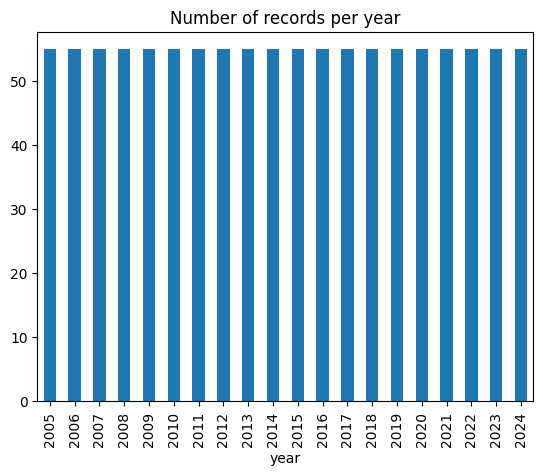

In [2434]:
final_raw_df.groupby("year").size().plot(kind="bar")
plt.title("Number of records per year")
plt.show()

### Data Quality Assessment

In [2435]:
def show_missing_values(df):
    coverage = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100,
        "present_count": df.notna().sum()
    }).sort_values("missing_percent", ascending=False)

    return coverage

show_missing_values(final_raw_df)

,missing_count,missing_percent,present_count
house_price_to_income_index,560,50.91,540
house_price_index,548,49.82,552
housing_overburden,444,40.36,656
living_with_parents,434,39.45,666
rent_price_index,373,33.91,727
mean_childbirth_age,253,23.00,847
fertility_rate,253,23.00,847
population,126,11.45,974
net_migration,121,11.00,979
year,0,0.00,1100


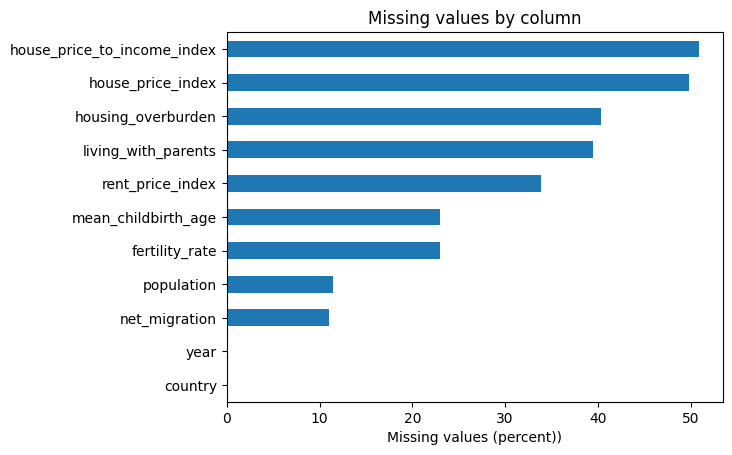

In [2436]:
missing_percent = (final_raw_df.isna().mean() * 100).sort_values(ascending=True)

missing_percent.plot(kind="barh")
plt.xlabel("Missing values (percent))")
plt.title("Missing values by column")
plt.show()

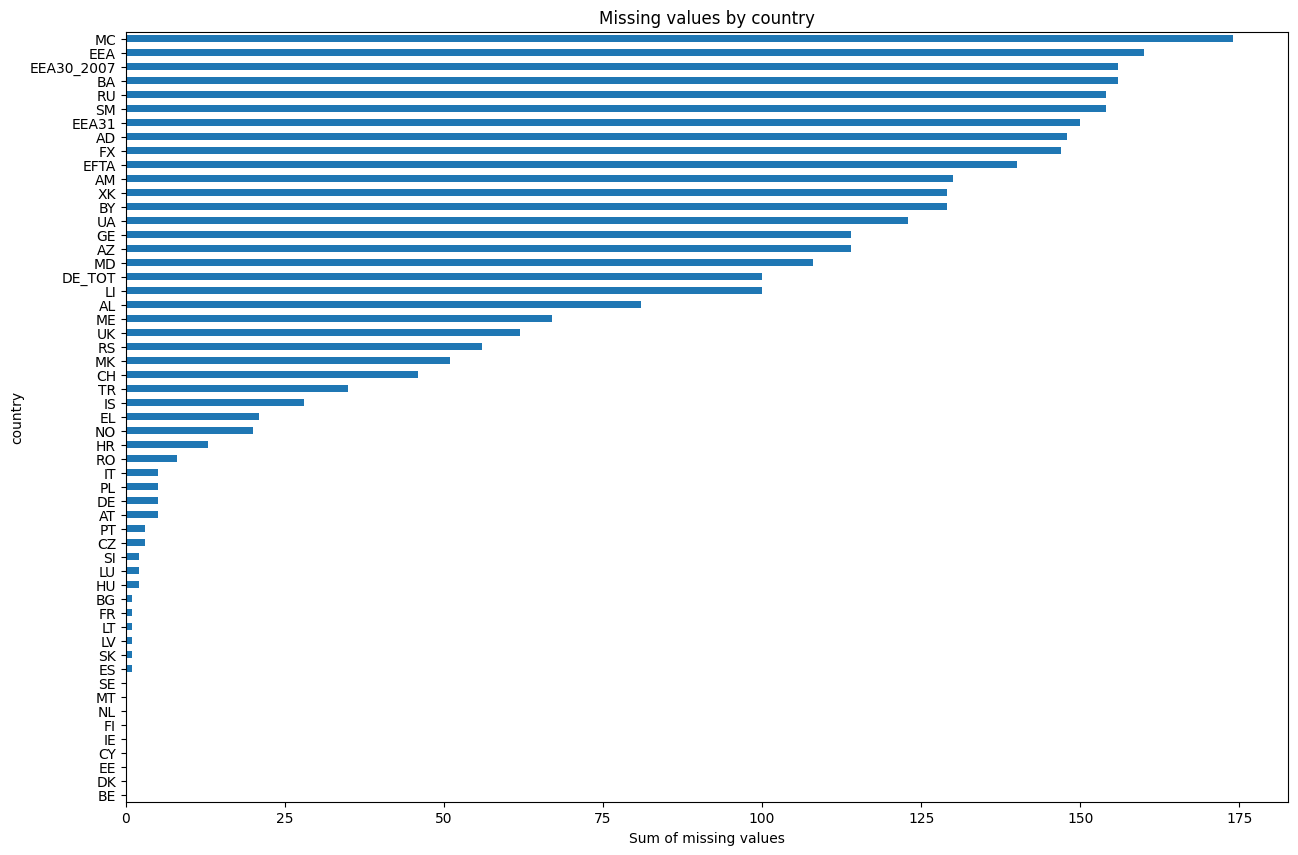

In [2437]:

indicator_cols = [col for col in final_raw_df.columns if col not in ["country", "year"]]

missing_by_country = (
    final_raw_df.groupby("country")[indicator_cols]
    .apply(lambda x: x.isna().sum().sum())
    .sort_values()
)

missing_by_country.plot(kind="barh", figsize=(15,10))
plt.xlabel("Sum of missing values")
plt.title("Missing values by country")
plt.show()

In [2438]:
final_raw_df.duplicated().sum()

np.int64(0)

In [2439]:
final_raw_df.duplicated(subset=["country", "year"]).sum()

np.int64(0)

## Data Preparation

In [2440]:
final_df = final_raw_df.copy()

### Data cleaning

In [2441]:
final_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,31.10,1.19,NaN


In [2442]:
numeric_columns = final_df.select_dtypes(include="number").columns.drop("year")
invalid = {}

for col in numeric_columns:
    invalid[col] = {
        "zero_values": (final_df[col] == 0).sum(),
        "negative_values": (final_df[col]<0).sum()
    }

to_investigate_df = pd.DataFrame(invalid).T
to_investigate_df

,zero_values,negative_values
house_price_to_income_index,0,0
housing_overburden,0,0
house_price_index,0,0
population,0,0
net_migration,26,276
living_with_parents,1,0
mean_childbirth_age,0,0
fertility_rate,0,0
rent_price_index,0,0


In [2443]:
final_df[final_df["living_with_parents"] == 0]

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
1037,TR,2022,NaN,11.20,611.40,84680273.00,0.80,0.00,29.20,1.63,221.23


In [ ]:
final_df.loc[final_df["living_with_parents"] == 0, "living_with_parents"] = pd.NA

### Missing values

In [ ]:
columns_to_verify = []
for col in final_df.columns:
    if col not in ["country", "year"]:
        columns_to_verify.append(col)

missing_percent_by_country = final_df.groupby("country")[columns_to_verify].apply(
    lambda x: x.isna().mean().mean() * 100
)
countries = missing_percent_by_country[missing_percent_by_country < 50].index
final_df = final_df[final_df["country"].isin(countries)]

In [2446]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
house_price_to_income_index,180,25.00,540
house_price_index,168,23.33,552
housing_overburden,65,9.03,655
living_with_parents,56,7.78,664
rent_price_index,23,3.19,697
mean_childbirth_age,12,1.67,708
fertility_rate,12,1.67,708
population,6,0.83,714
net_migration,5,0.69,715
year,0,0.00,720


In [2447]:
missing_price_to_income= final_df.groupby("country")["house_price_to_income_index"].apply(
    lambda x: x.isna().sum()
)
pd.DataFrame(missing_price_to_income[missing_price_to_income == 20])

,house_price_to_income_index
country,
AL,20
CH,20
IS,20
ME,20
MK,20
NO,20
RS,20
TR,20
UK,20


In [ ]:
countries_to_drop = missing_price_to_income[missing_price_to_income == 20].index
final_df = final_df[~final_df["country"].isin(countries_to_drop)].reset_index(drop=True)

house_price_index

In [2449]:
missing_house_price_index= final_df.groupby("country")["house_price_index"].apply(
    lambda x: x.isna().sum()
)
pd.DataFrame(missing_house_price_index[missing_house_price_index == 20])

,house_price_index
country,
EL,20


In [ ]:
countries_to_drop = missing_house_price_index[missing_house_price_index == 20].index
final_df = final_df[~final_df["country"].isin(countries_to_drop)].reset_index(drop=True)

In [2451]:
final_df["country"].nunique()

26

In [2452]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
house_price_index,38,7.31,482
housing_overburden,14,2.69,506
living_with_parents,7,1.35,513
house_price_to_income_index,0,0.00,520
year,0,0.00,520
country,0,0.00,520
population,0,0.00,520
net_migration,0,0.00,520
mean_childbirth_age,0,0.00,520
fertility_rate,0,0.00,520


In [ ]:
columns_to_interpolate = [
    "house_price_index",
    "housing_overburden",
    "living_with_parents"
]

final_df = final_df.sort_values(["country", "year"]).reset_index(drop=True)

for column in columns_to_interpolate:
    final_df[column] = (
        final_df
        .groupby("country")[column]
        .transform(lambda x: x.interpolate(method="linear", limit_direction="both"))
    )

In [2454]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
country,0,0.00,520
year,0,0.00,520
house_price_to_income_index,0,0.00,520
housing_overburden,0,0.00,520
house_price_index,0,0.00,520
population,0,0.00,520
net_migration,0,0.00,520
living_with_parents,0,0.00,520
mean_childbirth_age,0,0.00,520
fertility_rate,0,0.00,520


### Duplicates

### Feature Engineering

In [2487]:
final_df["housing_overburden"].describe()

count   520.00
mean      8.29
std       4.25
min       1.10
25%       5.00
50%       7.70
75%      10.30
max      24.20
Name: housing_overburden, dtype: float64

In [2491]:
final_df["housing_burden_category"] = pd.qcut(
    final_df["housing_overburden"],
    q=3,
    labels=["Low", "Medium", "High"]
)

final_df[["country", "year", "housing_burden_category"]]

,country,year,housing_burden_category
0,AT,2005,Low
1,AT,2006,Low
2,AT,2007,Low
3,AT,2008,Medium
4,AT,2009,Medium
...,...,...,...
515,SK,2020,Low
516,SK,2021,Medium
517,SK,2022,Low
518,SK,2023,Medium


## Exploratory Data Analysis

In [2455]:
final_df.shape

(520, 11)

In [ ]:
indicator_cols = [col for col in final_df.columns if col not in ["country", "year", , "housing_burden_category"]]

In [2456]:
final_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AT,2005,87.32,4.60,77.32,8201359.00,6.10,44.50,29.00,1.41,72.15
1,AT,2006,86.80,5.00,77.32,8254298.00,3.00,45.80,29.20,1.41,73.76
2,AT,2007,86.31,5.40,77.32,8282984.00,2.80,47.00,29.40,1.38,75.21
3,AT,2008,84.65,8.50,77.32,8307989.00,2.90,46.00,29.50,1.42,76.16
4,AT,2009,84.59,8.00,77.32,8335003.00,2.10,47.40,29.70,1.39,79.74


In [2485]:
print(f"Final set of countries: {final_df["country"].nunique()}")
print(f"Years: {final_df["year"].min()} - {final_df["year"].max()}")
print(f"Rows: {len(final_df)}")

Final set of countries: 26
Years: 2005 - 2024
Rows: 520


In [2458]:
final_df.describe()

,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
count,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00
mean,2014.50,101.47,8.29,117.35,16609375.82,3.60,49.88,30.15,1.53,100.83
std,5.77,16.87,4.25,33.32,21998031.54,7.60,14.87,1.33,0.20,19.17
min,2005.00,48.23,1.10,52.04,402668.00,-25.20,15.50,25.90,1.01,38.64
25%,2009.75,91.19,5.00,97.19,2942557.50,-0.10,41.75,29.40,1.38,90.85
50%,2014.50,98.66,7.70,107.52,7944966.00,2.60,52.80,30.35,1.50,100.00
75%,2019.25,108.06,10.30,131.28,16847148.25,5.93,60.60,31.10,1.66,108.45
max,2024.00,227.10,24.20,309.86,83456045.00,42.10,78.20,33.20,2.06,187.10


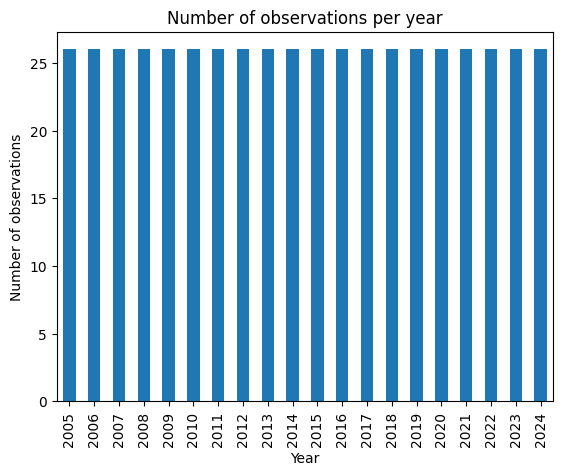

In [2459]:
final_df.groupby("year").size().plot(kind="bar")
plt.title("Number of observations per year")
plt.xlabel("Year")
plt.ylabel("Number of observations")
plt.show()

### Univariate Analysis (Distributions)

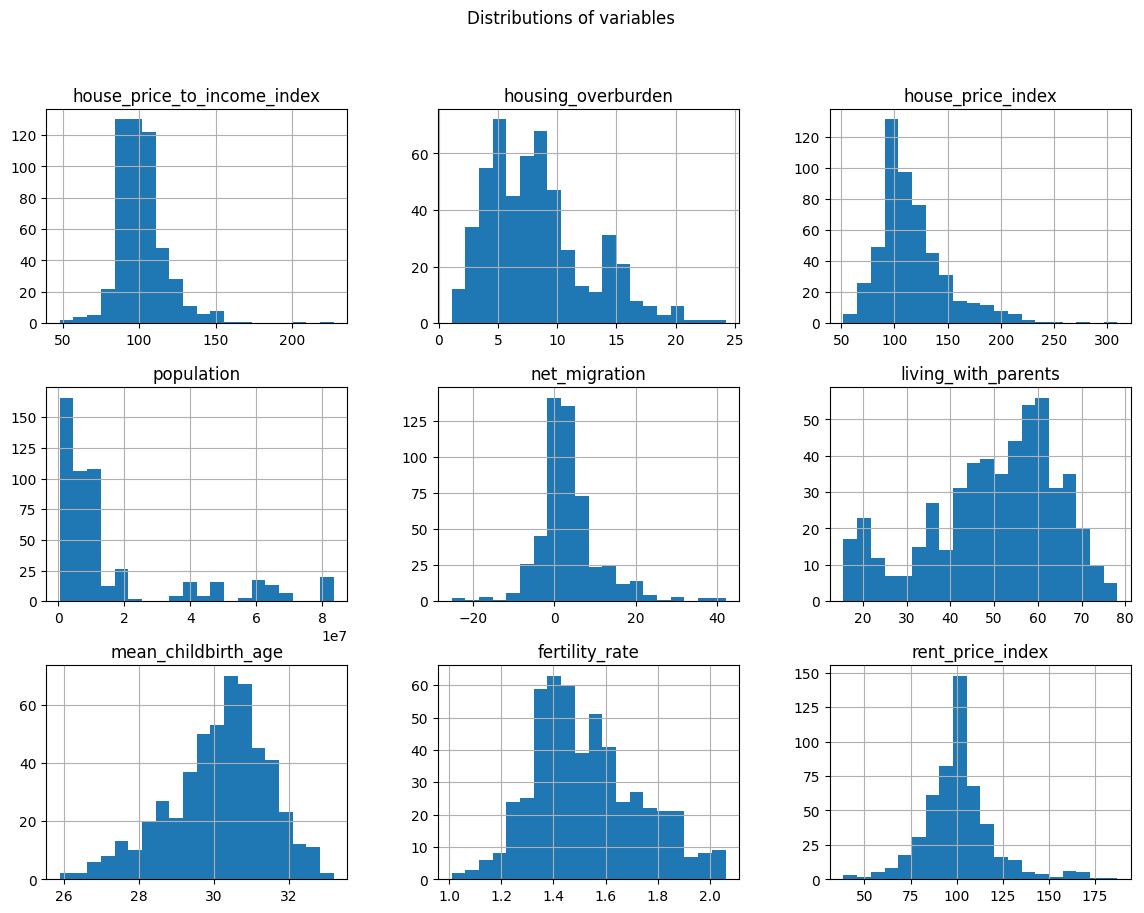

In [2460]:
final_df[indicator_cols].hist(bins=20, figsize=(14, 10))
plt.suptitle("Distributions of variables")
plt.show()

 ### Trends Analysis

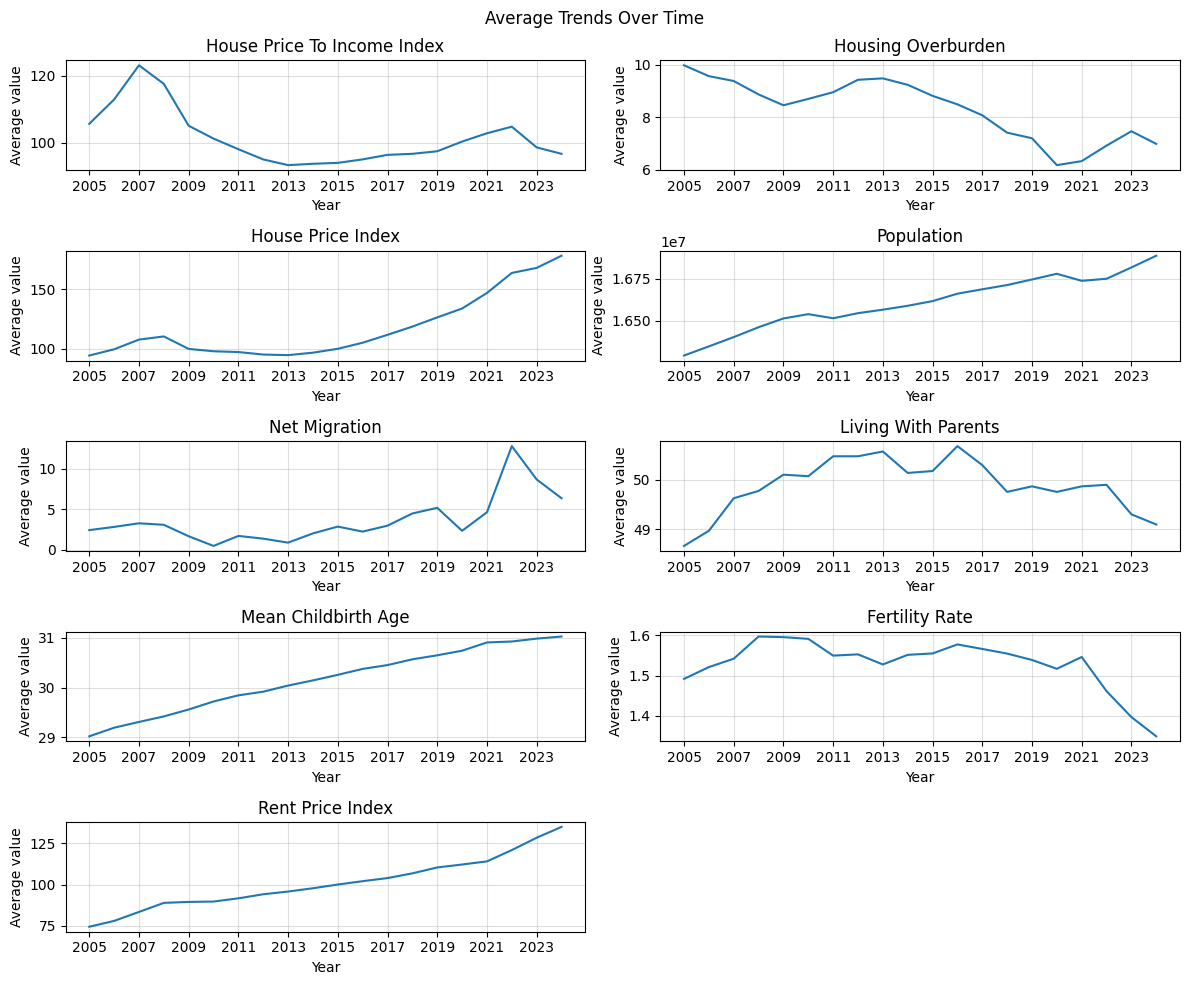

In [ ]:
yearly_avg = final_df.groupby("year")[indicator_cols].mean()
fig, axes  = plt.subplots(5,2, figsize=(12,10))
axes = axes.flatten()

for i, column in enumerate(indicator_cols):
    ax = axes[i]

    ax.plot(
        yearly_avg.index.astype(int),
        yearly_avg[column],
    )
    
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Year")
    ax.set_xticks(yearly_avg.index[::2])
    ax.set_ylabel("Average value")
    ax.grid(alpha=0.4)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Average Trends Over Time")
plt.tight_layout()
plt.show()

In [ ]:
main_variables_trends = (
    final_df.groupby("year")[
        ["house_price_index",
         "rent_price_index",
         "house_price_to_income_index"]
    ]
).mean()

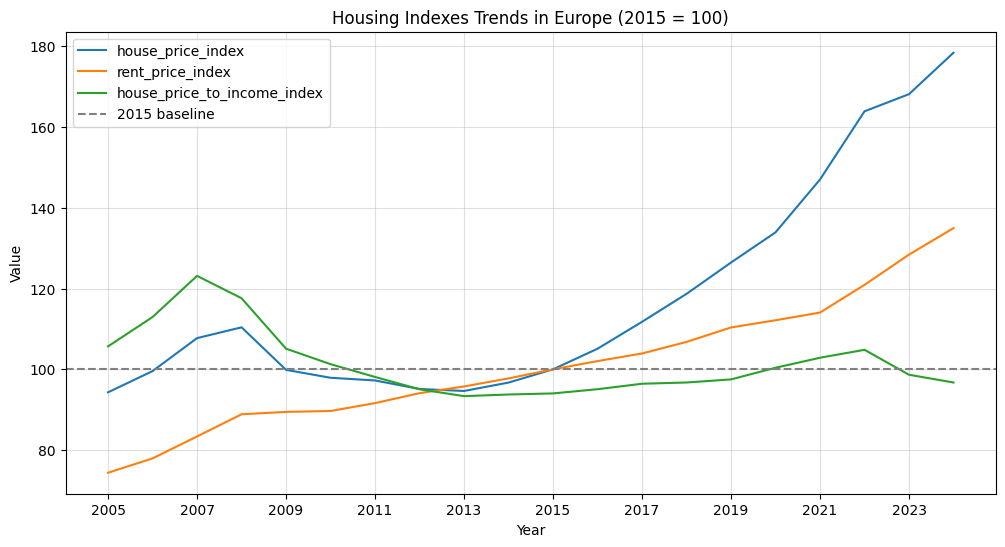

In [2463]:
plt.figure(figsize=(12,6))
for column in main_variables_trends.columns:
    plt.plot(main_variables_trends.index, main_variables_trends[column], label=column)
plt.axhline(100, color="gray", linestyle="--", label="2015 baseline")
plt.title("Housing Indexes Trends in Europe (2015 = 100)")
plt.xlabel("Year")
plt.xticks(main_variables_trends.index[::2])
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.4)

plt.show()

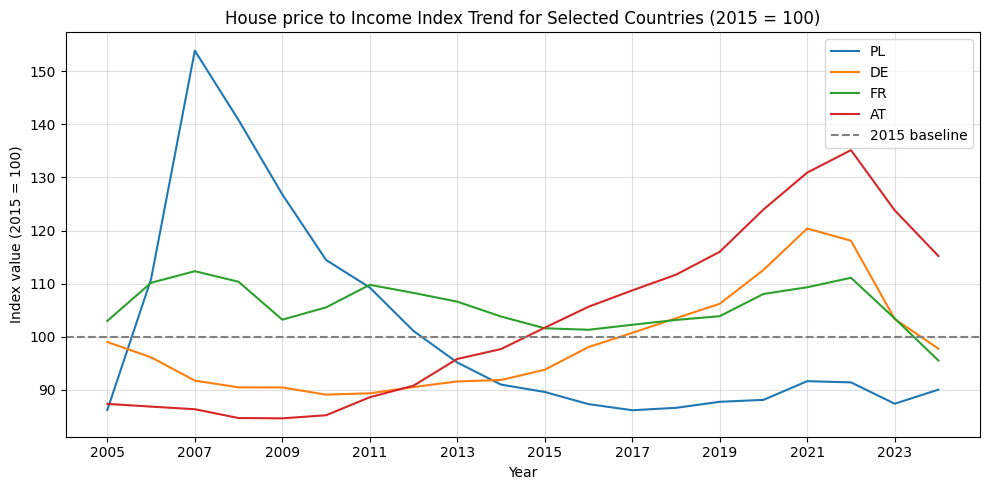

In [2464]:
selected_countries = ["PL", "DE", "FR", "AT"]

plt.figure(figsize=(10,5))
for country in selected_countries:
    country_data = final_df.loc[final_df["country"] == country]
    plt.plot(country_data["year"], country_data["house_price_to_income_index"], label=country)
    
plt.axhline(100, color="gray", linestyle="--", label="2015 baseline")
plt.xlabel("Year")
plt.xticks(sorted(final_df["year"].unique())[::2])
plt.ylabel("Index value (2015 = 100)")
plt.title("House price to Income Index Trend for Selected Countries (2015 = 100)")
plt.grid(alpha=0.4)
plt.legend()
plt.tight_layout()


plt.show()

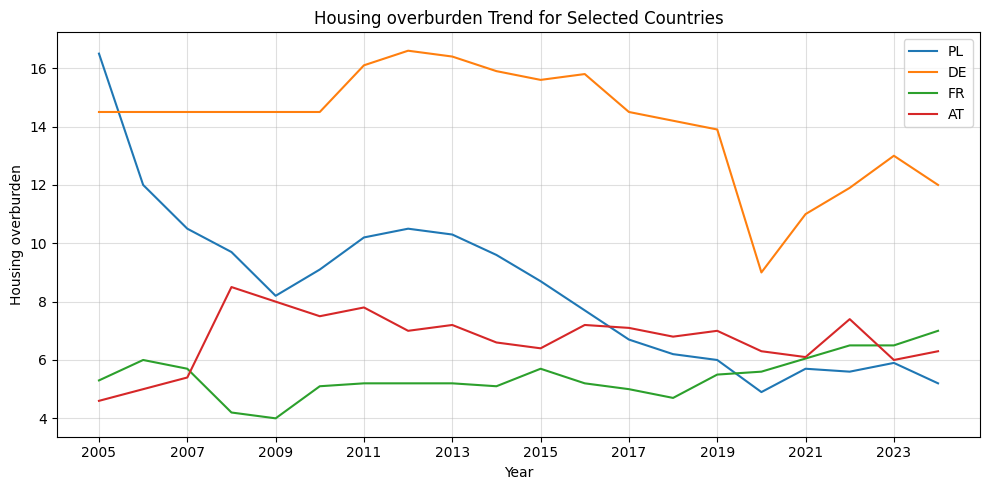

In [2465]:
plt.figure(figsize=(10,5))
for country in selected_countries:
    country_data = final_df.loc[final_df["country"] == country]
    plt.plot(country_data["year"], country_data["housing_overburden"], label=country)
    
plt.xlabel("Year")
plt.xticks(sorted(final_df["year"].unique())[::2])
plt.ylabel("Housing overburden")
plt.title("Housing overburden Trend for Selected Countries")
plt.grid(alpha=0.4)
plt.legend()
plt.tight_layout()


plt.show()

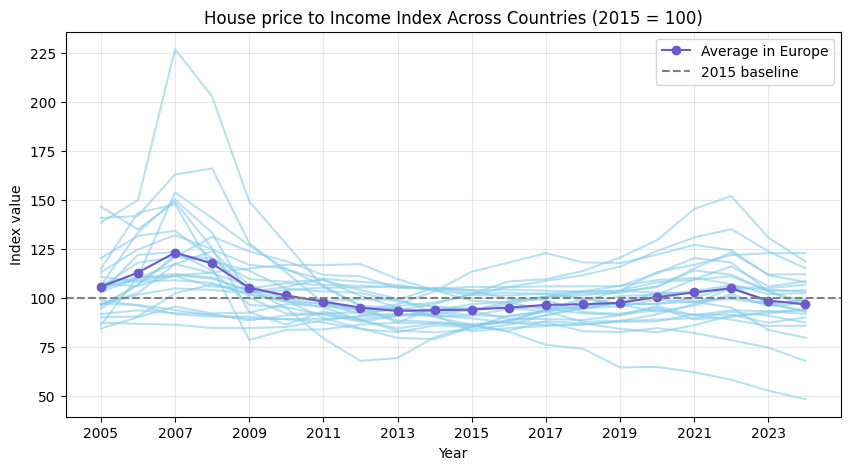

In [ ]:
main_column = "house_price_to_income_index"
yearly_avg= final_df.groupby("year")[main_column].mean()

plt.figure(figsize=(10, 5))

for country in final_df["country"].unique():
    country_data = final_df.loc[final_df["country"] == country]
    plt.plot(
        country_data["year"],
        country_data[main_column],
        color="skyblue",
        alpha=0.6
    )

plt.plot(
    yearly_avg.index,
    yearly_avg,
    color= "slateblue",
    marker = "o",
    label="Average in Europe"
)

plt.axhline(100, color="gray", linestyle="--", label="2015 baseline")
plt.title("House price to Income Index Across Countries (2015 = 100)")
plt.xlabel("Year")
plt.ylabel("Index value")
plt.xticks(sorted(final_df["year"].unique())[::2])
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [ ]:
def create_change(df, main_column):
    base_year = 2015
    latest_year = 2024

    base_data = df[df["year"] == base_year][["country", main_column]]
    latest_data = df[df["year"] == latest_year][["country", main_column]]
    change_df = base_data.merge(latest_data, on= "country", suffixes=("_2015", "_2024"))
    change_df["value_change"] = change_df[f"{main_column}_{latest_year}"] - change_df[f"{main_column}_{base_year}"]

    change_df_sorted = change_df.sort_values("value_change")
    return change_df_sorted

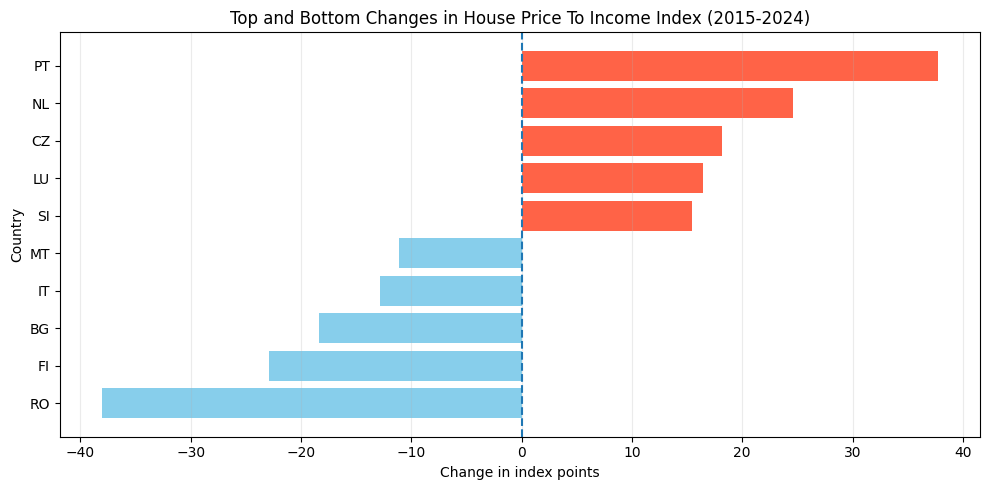

In [2468]:
main_column = "house_price_to_income_index"
change_df_sorted = create_change(final_df, main_column)
bottom = change_df_sorted.head(5)
top= change_df_sorted.tail(5)
top_bottom = pd.concat([bottom, top])

colors =[]
for value in top_bottom["value_change"]:
    if value > 0:
        colors.append("tomato")
    else:
        colors.append("skyblue")


plt.figure(figsize=(10, 5))
plt.barh(top_bottom["country"], top_bottom["value_change"], color=colors)
plt.axvline(0, linestyle="--")
plt.title(f"Top and Bottom Changes in {main_column.replace("_", " ").title()} (2015-2024)")
plt.xlabel("Change in index points")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

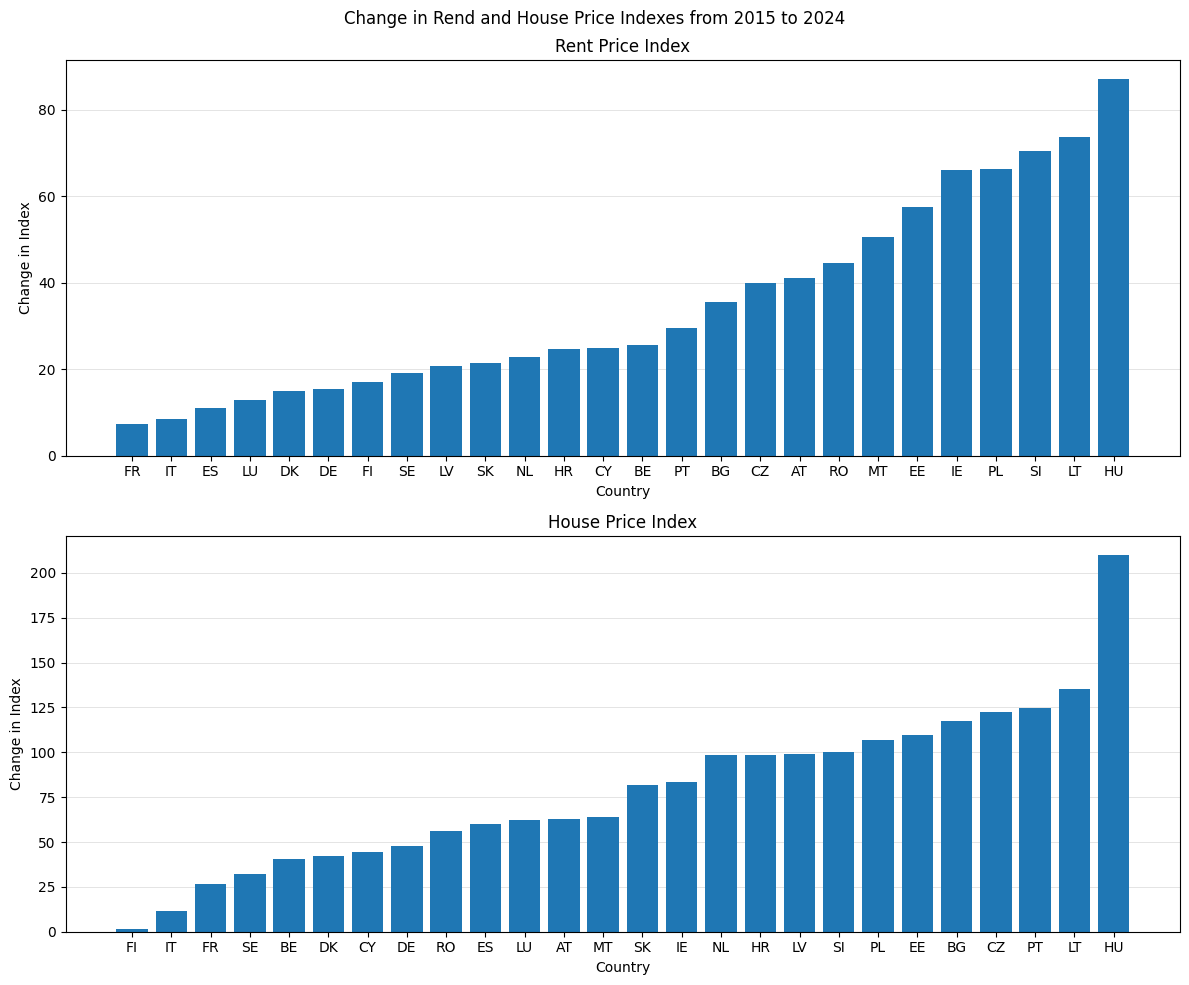

In [2469]:
rent_column = "rent_price_index"
rent_change = create_change(final_df, rent_column)

house_column = "house_price_index"
house_change = create_change(final_df, house_column)

fig, axes  = plt.subplots(2,1, figsize=(12,10))
ax = axes.flatten()
ax[0].bar(
    rent_change["country"],
    rent_change["value_change"]
)

ax[0].set_title(rent_column.replace("_", " ").title())
ax[0].set_xlabel("Country")
ax[0].set_ylabel("Change in Index")
ax[0].grid(axis="y", linewidth=0.6, alpha=0.4)
ax[0].set_axisbelow(True)

ax[1].bar(
    house_change["country"],
    house_change["value_change"]
)

ax[1].set_title(house_column.replace("_", " ").title())
ax[1].set_xlabel("Country")
ax[1].set_ylabel("Change in Index")
ax[1].grid(axis="y", linewidth=0.6, alpha=0.4)
ax[1].set_axisbelow(True)

plt.suptitle("Change in Rend and House Price Indexes from 2015 to 2024")
plt.tight_layout()
plt.show()


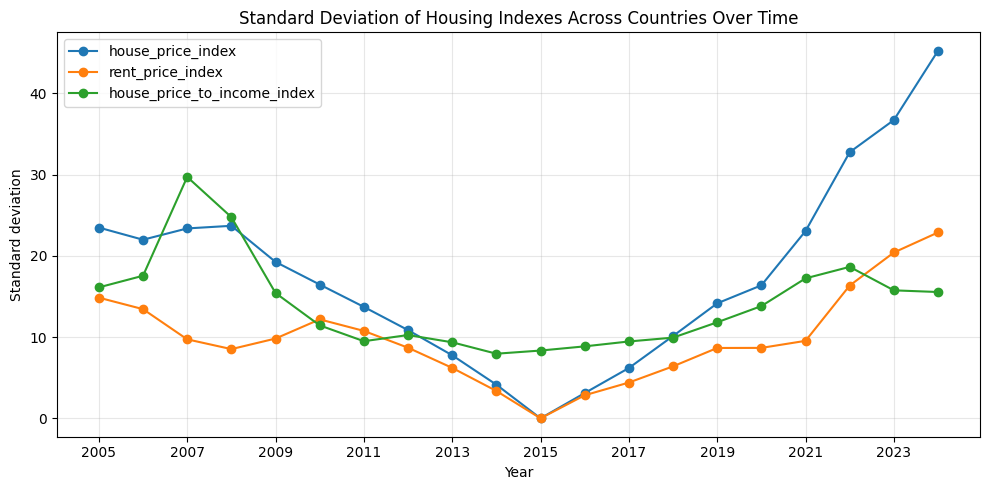

In [2470]:
main_variables = ["house_price_index", "rent_price_index", "house_price_to_income_index"]
std_per_year = final_df.groupby("year")[main_variables].std()

plt.figure(figsize=(10, 5))
for column in main_variables:
    plt.plot(std_per_year.index, std_per_year[column], marker="o", label=column)


plt.title("Standard Deviation of Housing Indexes Across Countries Over Time")
plt.xlabel("Year")
plt.ylabel("Standard deviation")
plt.xticks(sorted(final_df["year"].unique())[::2])

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Correlation Analysis

In [ ]:
corr_cols =  [col for col in final_raw_df.columns if col not in ["country", "year"]]

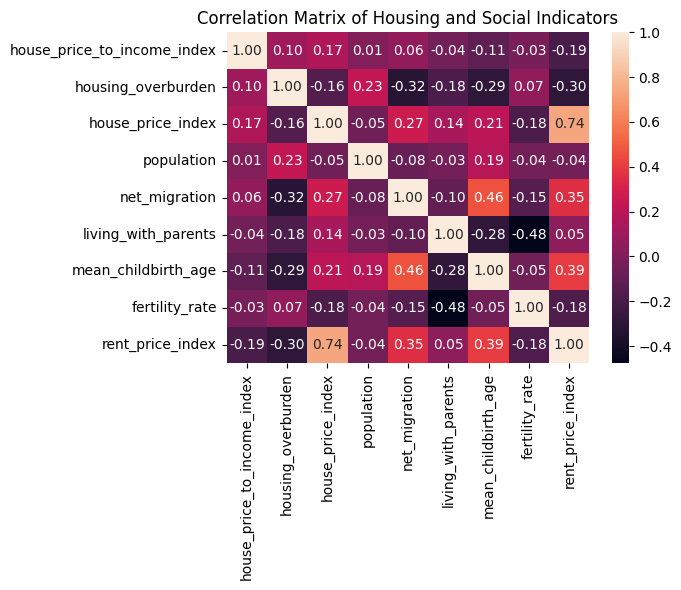

In [2472]:
corr = final_df[corr_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"    
)

plt.title("Correlation Matrix of Housing and Social Indicators")
plt.tight_layout()
plt.show()

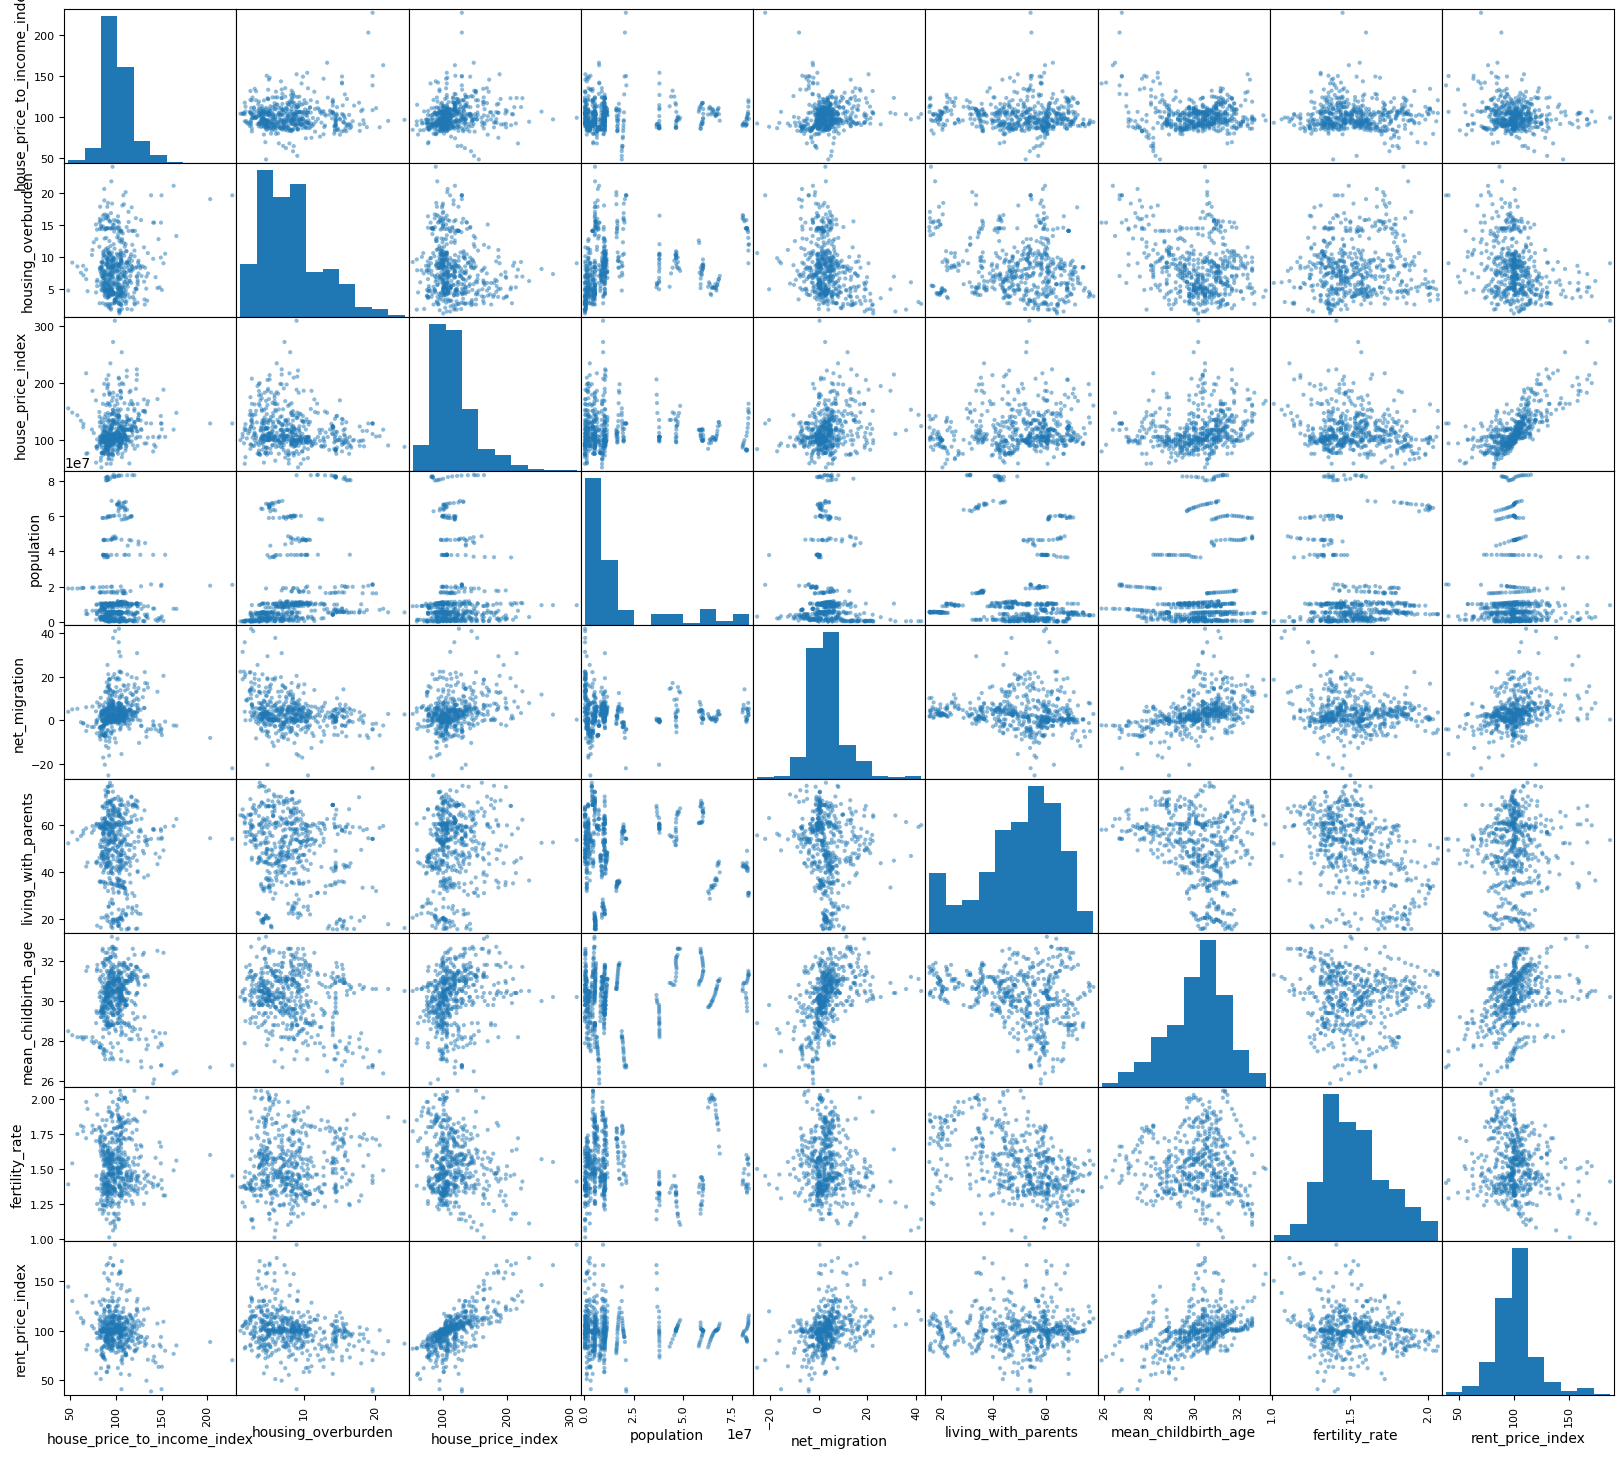

In [2473]:
pd.plotting.scatter_matrix(final_df[indicator_cols], figsize=(20, 18))
plt.show()

In [2474]:
corr_ranking = (
    corr
    .stack()
    .reset_index()
)
corr_ranking.columns = ["variable_1","variable_2","correlation"]
corr_ranking = corr_ranking[corr_ranking["variable_1"] != corr_ranking["variable_2"]]

corr_ranking["variables_pair"] = corr_ranking.apply(
    lambda row: tuple(sorted([row["variable_1"], row["variable_2"]])), axis=1)
corr_ranking = corr_ranking.drop_duplicates("variables_pair")

corr_ranking = corr_ranking.sort_values(by="correlation", key=lambda x: abs(x), ascending=False)

corr_ranking = corr_ranking[["variable_1", "variable_2", "correlation"]]
corr_ranking.head(10)

,variable_1,variable_2,correlation
26,house_price_index,rent_price_index,0.74
52,living_with_parents,fertility_rate,-0.48
42,net_migration,mean_childbirth_age,0.46
62,mean_childbirth_age,rent_price_index,0.39
44,net_migration,rent_price_index,0.35
13,housing_overburden,net_migration,-0.32
17,housing_overburden,rent_price_index,-0.30
15,housing_overburden,mean_childbirth_age,-0.29
51,living_with_parents,mean_childbirth_age,-0.28
22,house_price_index,net_migration,0.27


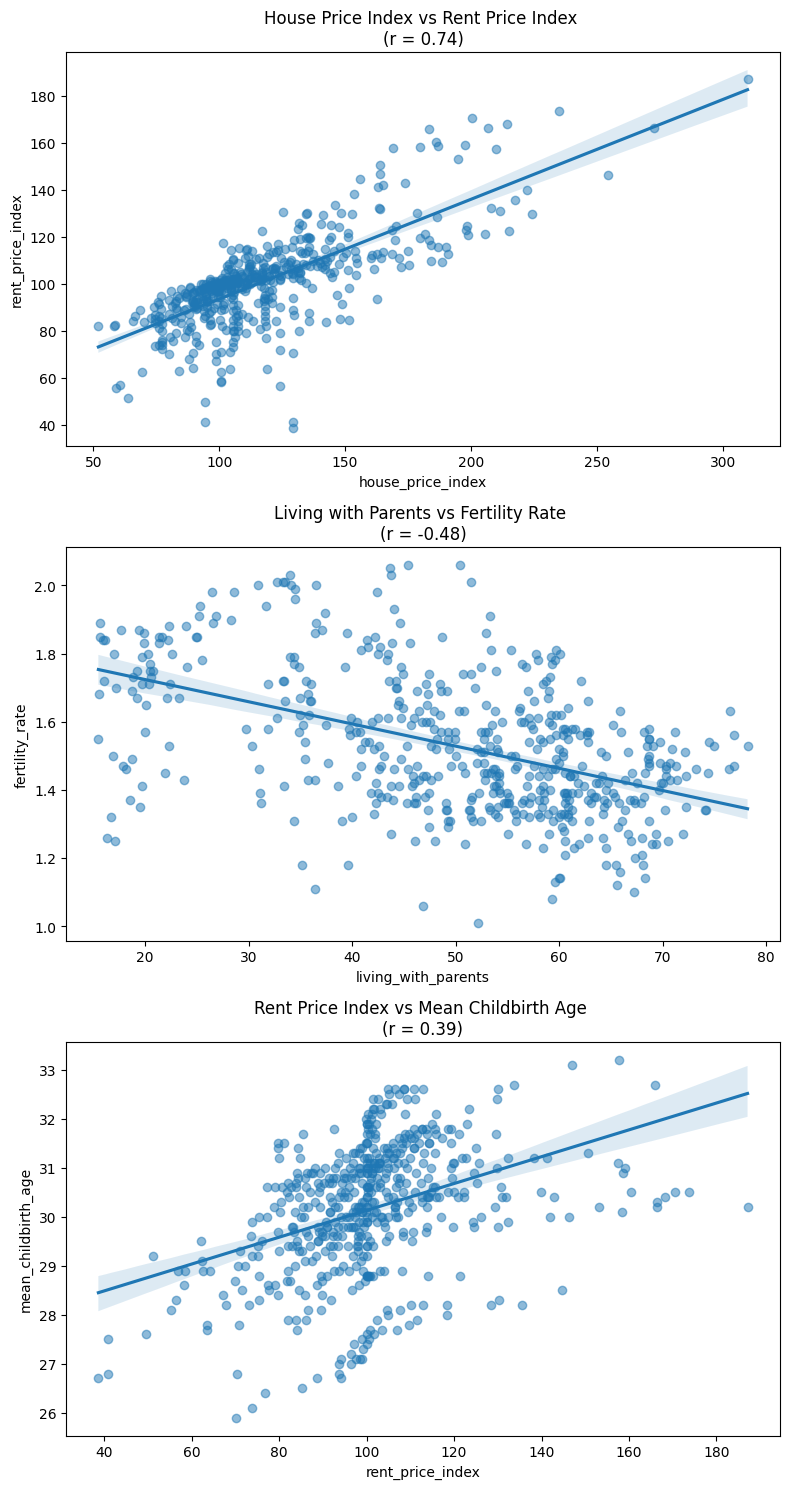

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(8, 15))

sns.regplot(
    data=final_df,
    x="house_price_index",
    y="rent_price_index",
    scatter_kws={"alpha":0.5},
    ax=axes[0]
)
axes[0].set_title("House Price Index vs Rent Price Index \n(r = 0.74)")

sns.regplot(
    data=final_df,
    x="living_with_parents",
    y="fertility_rate",
    scatter_kws={"alpha":0.5},
    ax=axes[1]
)

axes[1].set_title("Living with Parents vs Fertility Rate \n(r = -0.48)")

sns.regplot(
    data=final_df,
    x="rent_price_index",
    y="mean_childbirth_age",
    scatter_kws={"alpha": 0.5},
    ax=axes[2]
)
axes[2].set_title("Rent Price Index vs Mean Childbirth Age \n(r = 0.39)")

plt.tight_layout()
plt.show()

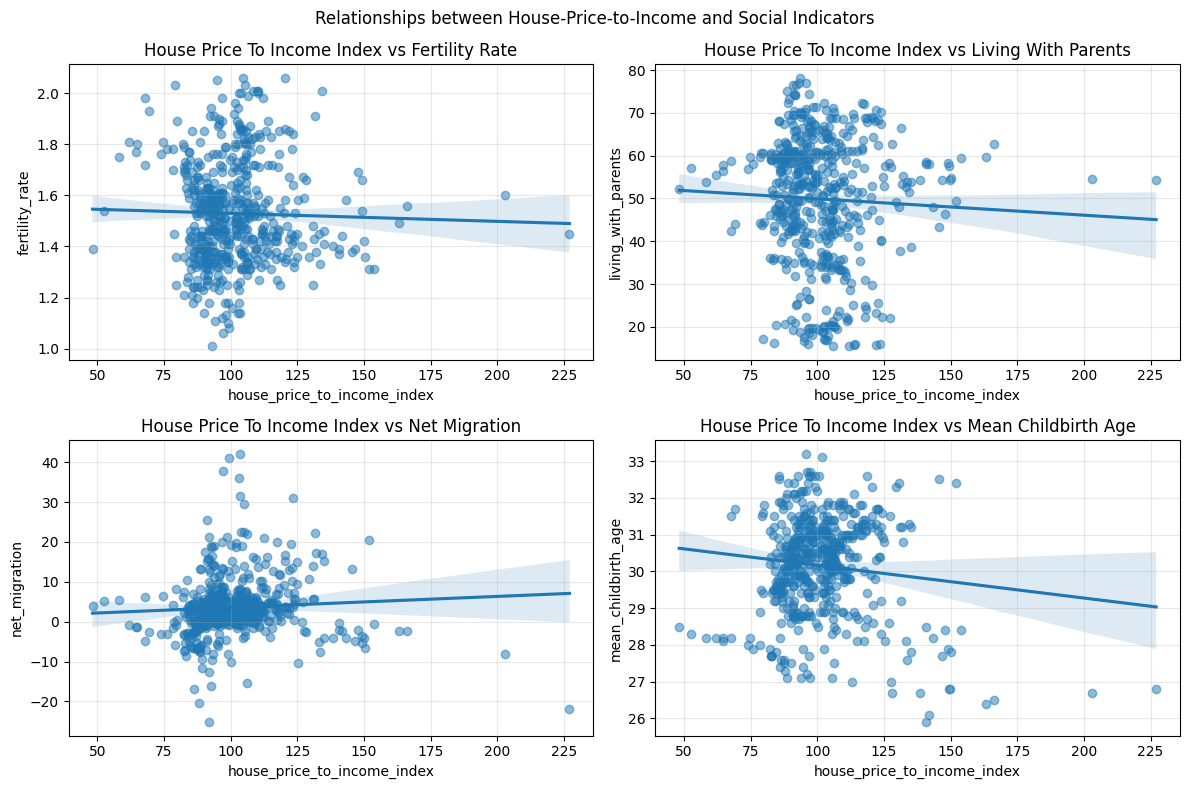

In [ ]:
pairs_for_scatterplot = [
    ("house_price_to_income_index", "fertility_rate"),
    ("house_price_to_income_index", "living_with_parents"),
    ("house_price_to_income_index", "net_migration"),
    ("house_price_to_income_index", "mean_childbirth_age")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, (x, y) in enumerate(pairs_for_scatterplot):
    ax = axes[i]
    
    sns.regplot(data=final_df, x=x, y=y, ax=ax, scatter_kws={"alpha": 0.5})
    
    ax.set_title(f"{x.replace("_", " ").title()} vs {y.replace("_", " ").title()}")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(alpha=0.3)

plt.suptitle("Relationships between House-Price-to-Income and Social Indicators")
plt.tight_layout()
plt.show()

### Outlier Analysis

In [2477]:
for_boxplots = [col for col in indicator_cols if col != "population"]
len(for_boxplots)


8

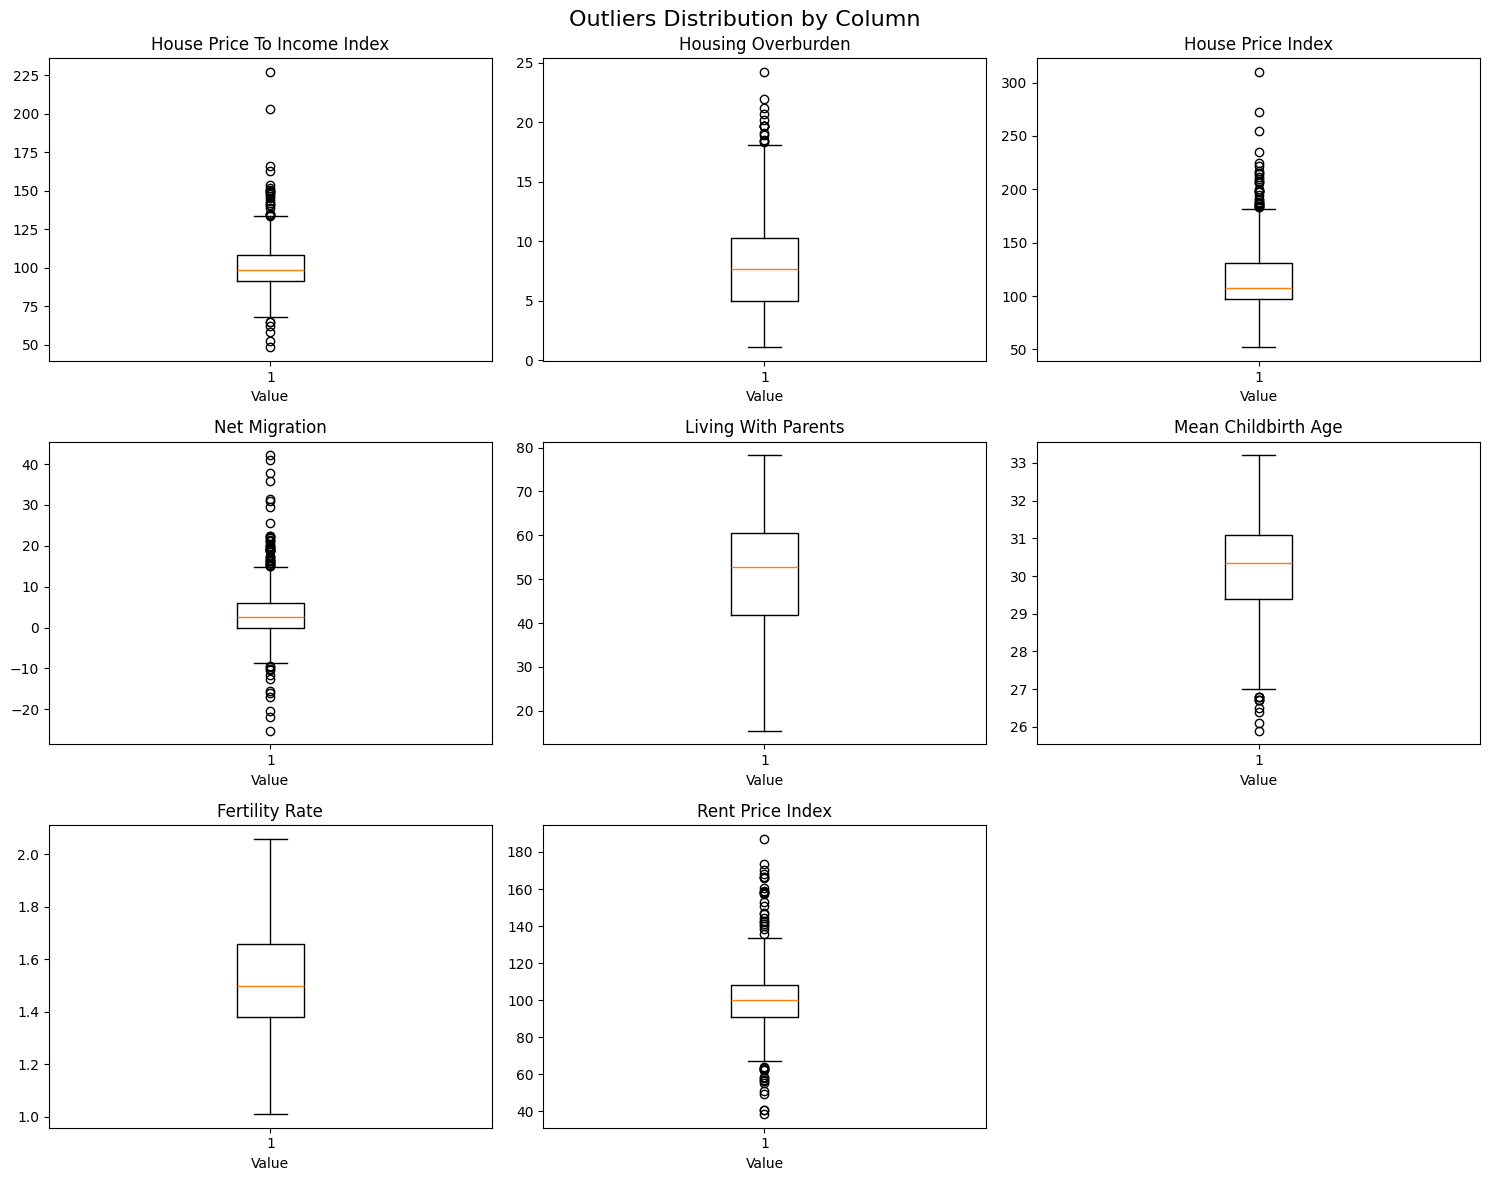

In [2478]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, column in enumerate(for_boxplots):
    ax = axes[i]
    ax.boxplot(final_df[column].dropna())
    
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Value")
   

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Outliers Distribution by Column", fontsize=16)
plt.tight_layout()
plt.show()

In [2479]:
outliers_summary = []
for column in for_boxplots:
    Q1 = final_df[column].quantile(0.25)
    Q3 = final_df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((final_df[column] < lower) | (final_df[column] > upper)).sum()
    
    outliers_summary.append({
        "variable": column,
        "outlier_count": outliers,
        "outlier_percent": outliers / len(final_df) * 100
    })

outliers_df = pd.DataFrame(outliers_summary).sort_values("outlier_count", ascending=False)
outliers_df

,variable,outlier_count,outlier_percent
3,net_migration,52,10.00
7,rent_price_index,40,7.69
2,house_price_index,31,5.96
0,house_price_to_income_index,28,5.38
1,housing_overburden,14,2.69
5,mean_childbirth_age,10,1.92
4,living_with_parents,0,0.00
6,fertility_rate,0,0.00


In [ ]:
def get_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (df[column] < lower) | (df[column] > upper)
   
    result = df.loc[outliers, ["country", "year", column]].copy()
    result["country_mean"] = result["country"].map(df.groupby("country")[column].mean()) 
    return result.sort_values(column, ascending=False)

In [2481]:
get_outliers(final_df, "net_migration").head(10)

,country,year,net_migration,country_mean
374,MT,2019,42.10,16.37
377,MT,2022,41.00,16.37
378,MT,2023,37.90,16.37
373,MT,2018,35.90,16.37
372,MT,2017,31.50,16.37
97,CZ,2022,30.90,4.63
157,EE,2022,29.50,2.09
317,LT,2022,25.50,-2.62
370,MT,2015,22.40,16.37
369,MT,2014,22.40,16.37


In [2482]:
net_migration_outliers = get_outliers(final_df, "net_migration")
pd.DataFrame(net_migration_outliers["country"].value_counts())

,count
country,
LU,12
MT,9
CY,6
LT,6
LV,5
IE,4
ES,2
HR,2
EE,1


In [2483]:
get_outliers(final_df, "house_price_to_income_index").head(10)

,country,year,house_price_to_income_index,country_mean
442,RO,2007,227.10,102.57
443,RO,2008,202.96,102.57
43,BG,2008,166.12,101.73
42,BG,2007,163.11,101.73
402,PL,2007,153.90,100.75
337,LU,2022,152.06,107.77
302,LT,2007,150.29,97.07
441,RO,2006,149.92,102.57
444,RO,2009,149.35,102.57
342,LV,2007,149.14,98.86


## Final Dataset Preparation

In [ ]:
final_df.to_csv("../data/final_dataset_draft.csv", index=False)